In [1]:

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

SEED = 42
EPOCHS = 3
BATCH_SIZE = 16
LEARNING_RATE = 1e-4
NUM_WORKERS = 2

DATA_PATH = "/kaggle/input/competitions/siim-isic-melanoma-classification"
CSV_PATH = os.path.join(DATA_PATH, "train.csv")
IMAGE_PATH = os.path.join(DATA_PATH, "jpeg", "train")

OUTPUT_PATH = "/kaggle/working/melanoma_vit_results"
os.makedirs(OUTPUT_PATH, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [2]:

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate image names:", df["image_name"].duplicated().sum())
print("Unique patients:", df["patient_id"].nunique())

assert os.path.isdir(IMAGE_PATH), "JPEG training folder not found!"


Dataset shape: (33126, 8)

Columns: ['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target']

First 5 rows:


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0



Target distribution:
target
0    32542
1      584
Name: count, dtype: int64

Missing values:
image_name                         0
patient_id                         0
sex                               65
age_approx                        68
anatom_site_general_challenge    527
diagnosis                          0
benign_malignant                   0
target                             0
dtype: int64

Duplicate image names: 0
Unique patients: 2056


In [3]:

split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(df, groups=df["patient_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=SEED
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["patient_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

for part in [train_df, val_df, test_df]:
    part.reset_index(drop=True, inplace=True)
    part["image_path"] = part["image_name"].apply(
        lambda name: os.path.join(IMAGE_PATH, name + ".jpg")
    )

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

print("Train-Val overlap:", len(train_patients & val_patients))
print("Train-Test overlap:", len(train_patients & test_patients))
print("Val-Test overlap:", len(val_patients & test_patients))

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: melanoma cases = {(part['target'] == 1).sum()}"
    )
    assert part["image_path"].map(os.path.isfile).all()


Train: 23043
Validation: 4903
Test: 5180
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
Train: melanoma cases = 399
Validation: melanoma cases = 73
Test: melanoma cases = 112


In [4]:

train_df.to_csv(
    os.path.join(OUTPUT_PATH, "train_split.csv"), index=False
)
val_df.to_csv(
    os.path.join(OUTPUT_PATH, "validation_split.csv"), index=False
)
test_df.to_csv(
    os.path.join(OUTPUT_PATH, "test_split.csv"), index=False
)

print("Split CSV files saved:")
print(os.listdir(OUTPUT_PATH))


Split CSV files saved:
['validation_split.csv', 'train_split.csv', 'test_split.csv']


In [5]:

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Training transformations:")
print(train_transform)

print("\nValidation/testing transformations:")
print(eval_transform)


Training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation/testing transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [6]:

class MelanomaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(row["target"]), dtype=torch.long
        )

        return image, label


train_dataset = MelanomaDataset(train_df, train_transform)
val_dataset = MelanomaDataset(val_df, eval_transform)
test_dataset = MelanomaDataset(test_df, eval_transform)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label.item())
print("Image dtype:", image.dtype)
print("All values finite:", torch.isfinite(image).all().item())


Training dataset: 23043
Validation dataset: 4903
Testing dataset: 5180
Image shape: torch.Size([3, 224, 224])
Label: 0
Image dtype: torch.float32
All values finite: True


In [7]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Training batches: 1441
Validation batches: 307
Testing batches: 324
Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])


In [8]:

weights = ViT_B_16_Weights.IMAGENET1K_V1

model = vit_b_16(weights=weights)

# Replace the original classification head with 2 outputs
in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, 2)

model = model.to(device)

print("Model: ViT-B/16")
print("Output classes:", model.heads.head.out_features)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", device)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 248MB/s]


Model: ViT-B/16
Output classes: 2
Parameters: 85800194
Device: cuda


In [9]:

counts = train_df["target"].value_counts().reindex(
    [0, 1], fill_value=0
)

class_weights = torch.tensor(
    [
        len(train_df) / (2.0 * counts[0]),
        len(train_df) / (2.0 * counts[1])
    ],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

print("Class counts:", counts.to_dict())
print("Class weights:", class_weights.tolist())
print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Class counts: {0: 22644, 1: 399}
Class weights: [0.50881028175354, 28.875940322875977]
Loss: CrossEntropyLoss()
Optimizer: AdamW


In [10]:

best_auc = -1.0
history = []

best_path = os.path.join(OUTPUT_PATH, "best_vit.pth")
latest_path = os.path.join(OUTPUT_PATH, "latest_vit.pth")
history_path = os.path.join(OUTPUT_PATH, "training_history.csv")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    total_seen = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Train"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type, enabled=use_amp
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        total_seen += labels.size(0)

    train_loss = total_loss / total_seen

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_seen = 0
    y_true, y_prob, y_pred = [], [], []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc="Validation"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            probs = torch.softmax(outputs.float(), dim=1)[:, 1]

            val_loss_sum += loss.item() * labels.size(0)
            val_seen += labels.size(0)

            y_true.extend(labels.cpu().numpy())
            y_prob.extend(probs.cpu().numpy())
            y_pred.extend(outputs.argmax(dim=1).cpu().numpy())

    val_loss = val_loss_sum / val_seen
    val_acc = accuracy_score(y_true, y_pred)
    val_auc = roc_auc_score(y_true, y_prob)

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_acc,
        "validation_roc_auc": val_auc
    }
    history.append(row)

    print(f"\nEpoch {epoch+1}")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Validation ROC-AUC: {val_auc:.4f}")

    # Save latest checkpoint and history
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_auc": max(best_auc, val_auc),
        "history": history
    }, latest_path)

    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), best_path)
        print("Best checkpoint saved.")

print("\nTraining finished.")
print("Best validation ROC-AUC:", round(best_auc, 4))


Epoch 1/3 - Train:   0%|          | 0/1441 [00:00<?, ?it/s]

Validation:   0%|          | 0/307 [00:00<?, ?it/s]


Epoch 1
Train loss: 0.4851
Validation loss: 0.4279
Validation accuracy: 0.9814
Validation ROC-AUC: 0.7015
Best checkpoint saved.


Epoch 2/3 - Train:   0%|          | 0/1441 [00:00<?, ?it/s]

Validation:   0%|          | 0/307 [00:00<?, ?it/s]


Epoch 2
Train loss: 0.4449
Validation loss: 0.4303
Validation accuracy: 0.9851
Validation ROC-AUC: 0.7357
Best checkpoint saved.


Epoch 3/3 - Train:   0%|          | 0/1441 [00:00<?, ?it/s]

Validation:   0%|          | 0/307 [00:00<?, ?it/s]


Epoch 3
Train loss: 0.4295
Validation loss: 0.4074
Validation accuracy: 0.9851
Validation ROC-AUC: 0.7498
Best checkpoint saved.

Training finished.
Best validation ROC-AUC: 0.7498


In [11]:

model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

y_true, y_prob, y_pred = [], [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Test evaluation"):
        images = images.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type, enabled=use_amp
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)[:, 1]

        y_true.extend(labels.numpy())
        y_prob.extend(probabilities.cpu().numpy())
        y_pred.extend(outputs.argmax(dim=1).cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall = recall_score(y_true, y_pred, zero_division=0)
test_f1 = f1_score(y_true, y_pred, zero_division=0)
test_auc = roc_auc_score(y_true, y_prob)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

results = {
    "model": "ViT-B/16",
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1_score": float(test_f1),
    "test_roc_auc": float(test_auc),
    "confusion_matrix": cm.tolist(),
    "best_validation_roc_auc": float(best_auc)
}

print("\nFINAL TEST RESULTS")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")
print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Non-melanoma", "Melanoma"],
    zero_division=0
))

with open(os.path.join(OUTPUT_PATH, "test_metrics.json"), "w") as f:
    json.dump(results, f, indent=4)

pd.DataFrame([{
    key: value for key, value in results.items()
    if key != "confusion_matrix"
}]).to_csv(
    os.path.join(OUTPUT_PATH, "test_metrics.csv"), index=False
)


Test evaluation:   0%|          | 0/324 [00:00<?, ?it/s]


FINAL TEST RESULTS
Accuracy:  0.9784
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
ROC-AUC:   0.7595

Confusion matrix:
[[5068    0]
 [ 112    0]]

Classification report:
              precision    recall  f1-score   support

Non-melanoma       0.98      1.00      0.99      5068
    Melanoma       0.00      0.00      0.00       112

    accuracy                           0.98      5180
   macro avg       0.49      0.50      0.49      5180
weighted avg       0.96      0.98      0.97      5180



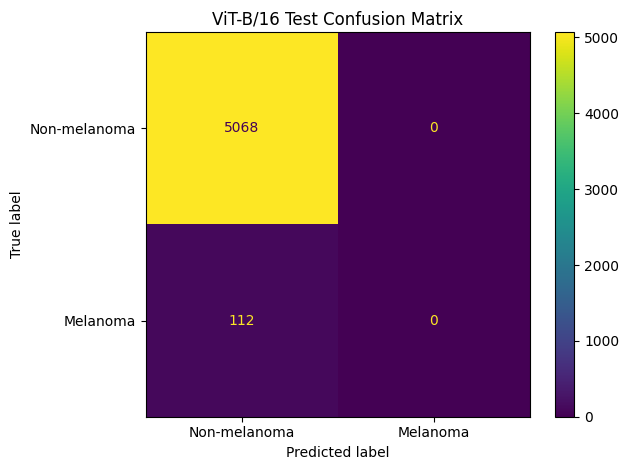

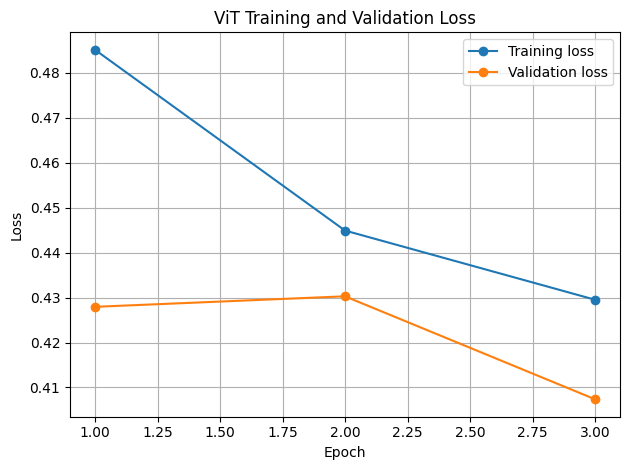

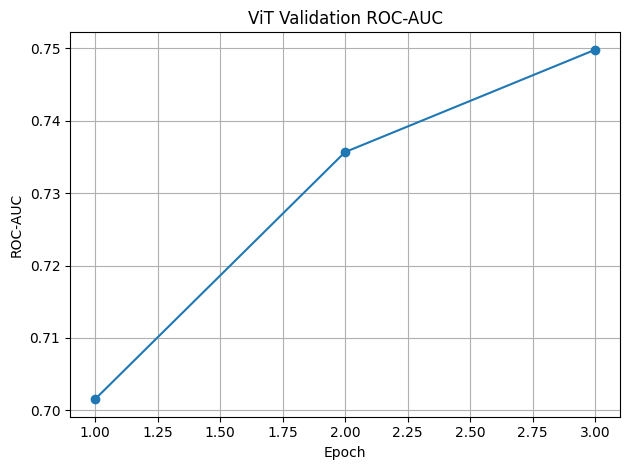


All saved output files:
best_vit.pth
confusion_matrix.png
latest_vit.pth
loss_curve.png
test_metrics.csv
test_metrics.json
test_split.csv
train_split.csv
training_history.csv
validation_auc_curve.png
validation_split.csv


In [12]:

# Confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-melanoma", "Melanoma"]
)
disp.plot(values_format="d")
plt.title("ViT-B/16 Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# Training and validation loss
history_df = pd.read_csv(history_path)

plt.figure()
plt.plot(history_df["epoch"], history_df["train_loss"],
         marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["validation_loss"],
         marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, "loss_curve.png"), dpi=200)
plt.show()

# Validation ROC-AUC
plt.figure()
plt.plot(history_df["epoch"], history_df["validation_roc_auc"],
         marker="o")
plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("ViT Validation ROC-AUC")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "validation_auc_curve.png"), dpi=200
)
plt.show()

print("\nAll saved output files:")
for filename in sorted(os.listdir(OUTPUT_PATH)):
    print(filename)
